In [17]:
import numpy as np
from scipy.stats import binom
import matplotlib.pyplot as plt 
import pandas as pd



In [18]:
df = pd.read_csv("matches.csv")
df.head()

,id,season,city,date,team1,team2,toss_winner,toss_decision,result,dl_applied,winner,win_by_runs,win_by_wickets,player_of_match,venue,umpire1,umpire2,umpire3
0,1,2017,Hyderabad,2017-04-05,Sunrisers Hyderabad,Royal Challengers Bangalore,Royal Challengers Bangalore,field,normal,0,Sunrisers Hyderabad,35,0,Yuvraj Singh,"Rajiv Gandhi International Stadium, Uppal",AY Dandekar,NJ Llong,NaN
1,2,2017,Pune,2017-04-06,Mumbai Indians,Rising Pune Supergiant,Rising Pune Supergiant,field,normal,0,Rising Pune Supergiant,0,7,SPD Smith,Maharashtra Cricket Association Stadium,A Nand Kishore,S Ravi,NaN
2,3,2017,Rajkot,2017-04-07,Gujarat Lions,Kolkata Knight Riders,Kolkata Knight Riders,field,normal,0,Kolkata Knight Riders,0,10,CA Lynn,Saurashtra Cricket Association Stadium,Nitin Menon,CK Nandan,NaN
3,4,2017,Indore,2017-04-08,Rising Pune Supergiant,Kings XI Punjab,Kings XI Punjab,field,normal,0,Kings XI Punjab,0,6,GJ Maxwell,Holkar Cricket Stadium,AK Chaudhary,C Shamshuddin,NaN
4,5,2017,Bangalore,2017-04-08,Royal Challengers Bangalore,Delhi Daredevils,Royal Challengers Bangalore,bat,normal,0,Royal Challengers Bangalore,15,0,KM Jadhav,M Chinnaswamy Stadium,NaN,NaN,NaN


In [19]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 756 entries, 0 to 755
Data columns (total 18 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   id               756 non-null    int64
 1   season           756 non-null    int64
 2   city             749 non-null    str  
 3   date             756 non-null    str  
 4   team1            756 non-null    str  
 5   team2            756 non-null    str  
 6   toss_winner      756 non-null    str  
 7   toss_decision    756 non-null    str  
 8   result           756 non-null    str  
 9   dl_applied       756 non-null    int64
 10  winner           752 non-null    str  
 11  win_by_runs      756 non-null    int64
 12  win_by_wickets   756 non-null    int64
 13  player_of_match  752 non-null    str  
 14  venue            756 non-null    str  
 15  umpire1          754 non-null    str  
 16  umpire2          754 non-null    str  
 17  umpire3          119 non-null    str  
dtypes: int64(5), str(13)


In [20]:
df.describe()

,id,season,dl_applied,win_by_runs,win_by_wickets
count,756.000000,756.000000,756.000000,756.000000,756.000000
mean,1792.178571,2013.444444,0.025132,13.283069,3.350529
std,3464.478148,3.366895,0.156630,23.471144,3.387963
min,1.000000,2008.000000,0.000000,0.000000,0.000000
25%,189.750000,2011.000000,0.000000,0.000000,0.000000
50%,378.500000,2013.000000,0.000000,0.000000,4.000000
75%,567.250000,2016.000000,0.000000,19.000000,6.000000
max,11415.000000,2019.000000,1.000000,146.000000,10.000000


In [21]:
df["success"] = (df["win_by_runs"] >= 50).astype(int)
print(df["success"].value_counts())

success
0    702
1     54
Name: count, dtype: int64


In [22]:
p = df["success"].mean()
n = 10
print("Probability of success:", p)

Probability of success: 0.07142857142857142


In [23]:
x = np.arange(0, n + 1)

pmf = binom.pmf(x,n,p)
cdf = binom.cdf(x,n,p)



In [24]:
mean, var = binom.stats(n, p, moments="mv")
std_dev = np.sqrt(var)

print("Probability of success:", p)
print("Mean (Expected successes):", mean)
print("Variance:", var)
print("Standard Deviation:", std_dev)

Probability of success: 0.07142857142857142
Mean (Expected successes): 0.7142857142857142
Variance: 0.6632653061224489
Standard Deviation: 0.8144110179279557


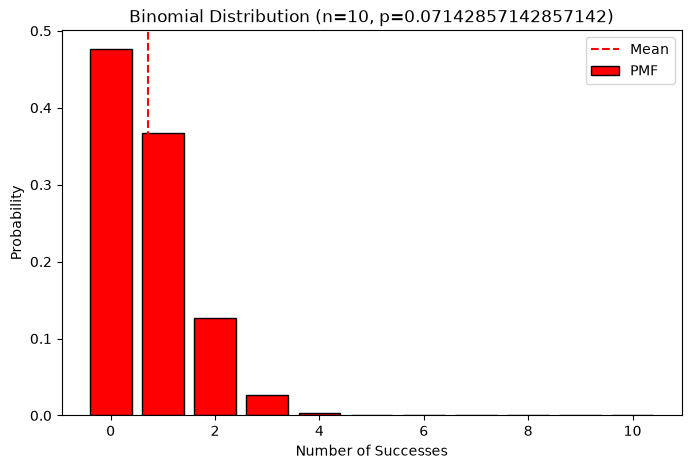

In [25]:
plt.figure(figsize=(8, 5))
plt.bar(x, pmf, color='red', edgecolor='black', label='PMF')
plt.axvline(mean, color='red', linestyle='--', label='Mean')
plt.title(f'Binomial Distribution (n={n}, p={p})')
plt.xlabel('Number of Successes')
plt.ylabel('Probability')
plt.legend()
plt.show()

Probability that exactly 5 out of 20 matches were won by at least 50 runs:

In [26]:
prob_5 = binom.pmf(5, n, p)

print("P(X = 5):", prob_5)

P(X = 5): 0.0003234721875358009


Probability that at most 5 matches satisfy the condition:

In [27]:


prob_at_most_5 = binom.cdf(5, n, p)

print("P(X <= 5):", prob_at_most_5)

P(X <= 5): 0.9999783264127572
